# Exploración · Bank Marketing

Leonardo Peraza Alavez · TC5061

Este notebook conserva únicamente carga y EDA. El código reutilizable está en el paquete `bank_marketing`, creado dentro de la estructura Cookiecutter Data Science. La experimentación se ejecuta con `train.py` o MLflow Projects. Se explora únicamente entrenamiento.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from bank_marketing.dataset import cargar_datos, dividir_datos

X, y, huella = cargar_datos()
X_train, X_valid, y_train, y_valid, n_prueba = dividir_datos(X, y, seed=42)
print("Filas:", len(X), "Variables de entrada:", X.shape[1])
print("Entrenamiento:", len(X_train))
print("Validación:", len(X_valid), "Prueba reservada:", n_prueba)
display(X_train.head())

Filas: 45211 Variables de entrada: 15
Entrenamiento: 27126
Validación: 9042 Prueba reservada: 9043


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
10333,43,services,married,secondary,no,2478,yes,no,unknown,12,jun,1,-1,0,unknown
9723,40,blue-collar,married,primary,no,676,no,no,unknown,9,jun,1,-1,0,unknown
22764,39,technician,married,secondary,no,3825,no,yes,cellular,25,aug,6,-1,0,unknown
23223,42,technician,divorced,secondary,no,324,yes,no,cellular,27,aug,2,-1,0,unknown
5594,31,blue-collar,married,secondary,no,631,yes,no,unknown,23,may,4,-1,0,unknown


## Estructura

El CSV original tiene 45,211 filas y 17 columnas, incluida la etiqueta `y`, que indica si se suscribió un depósito. Se excluye `duration` porque solo se conoce al terminar la llamada. Quedan 15 variables de entrada.

Los valores `unknown` de ocupación, educación y canal siguen visibles en este EDA. El transformador propio `BankCleaner` los convierte a faltantes dentro del pipeline. La imputación, codificación y escalado se ajustan solo con entrenamiento.

In [2]:
estructura = pd.DataFrame(
    {
        "tipo": X_train.dtypes.astype(str),
        "faltantes": X_train.isna().sum(),
        "unknown": X_train.eq("unknown").sum(),
    }
)
display(estructura)
display(X_train.describe().T.round(2))
display(X_train.select_dtypes(exclude="number").describe().T)

,tipo,faltantes,unknown
age,int64,0,0
job,str,0,179
marital,str,0,0
education,str,0,1100
default,str,0,0
balance,int64,0,0
housing,str,0,0
loan,str,0,0
contact,str,0,7790
day,int64,0,0


,count,mean,std,min,25%,50%,75%,max
age,27126.0,40.89,10.63,18.0,33.0,39.0,48.00,95.0
balance,27126.0,1368.13,3087.75,-6847.0,73.0,454.0,1425.75,81204.0
day,27126.0,15.80,8.32,1.0,8.0,16.0,21.00,31.0
campaign,27126.0,2.76,3.10,1.0,1.0,2.0,3.00,63.0
pdays,27126.0,40.07,100.40,-1.0,-1.0,-1.0,-1.00,871.0
previous,27126.0,0.58,1.97,0.0,0.0,0.0,0.00,58.0


,count,unique,top,freq
job,27126,12,blue-collar,5814
marital,27126,3,married,16286
education,27126,4,secondary,13965
default,27126,2,no,26629
housing,27126,2,yes,15150
loan,27126,2,no,22723
contact,27126,3,cellular,17595
month,27126,12,may,8259
poutcome,27126,4,unknown,22240


## Distribuciones y relación entre variables

Se observa el desbalance de la etiqueta, la distribución de las variables numéricas y la asociación entre el resultado previo y la suscripción actual. Estas relaciones no demuestran causalidad.

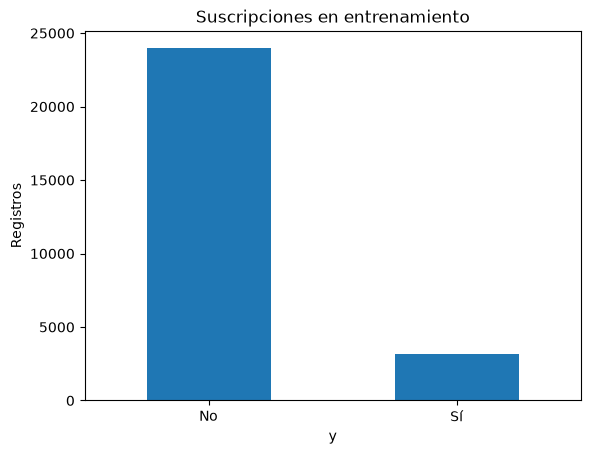

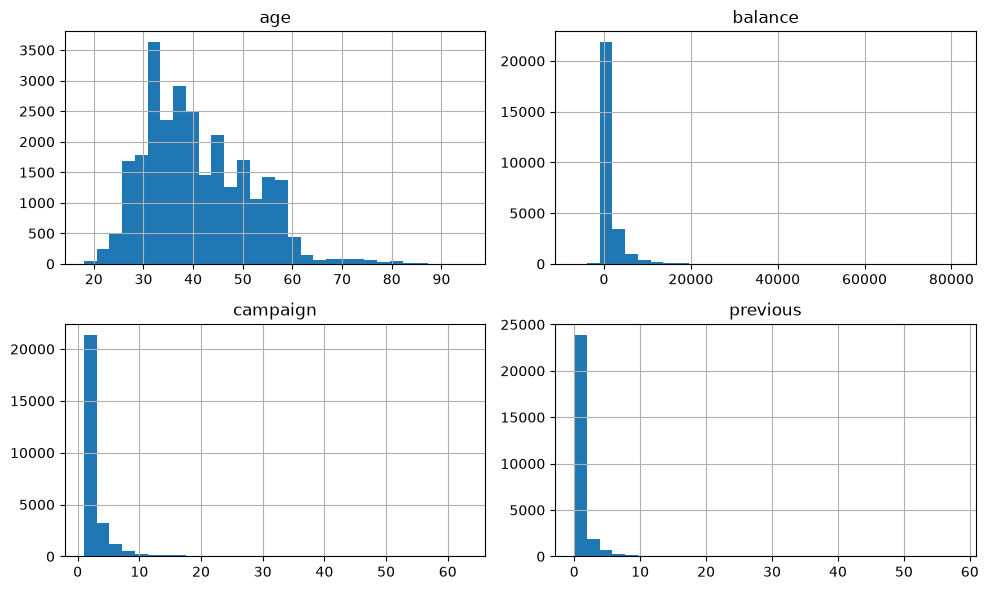

,mean,count
poutcome,,
failure,0.125,2876
other,0.165,1117
success,0.638,893
unknown,0.093,22240


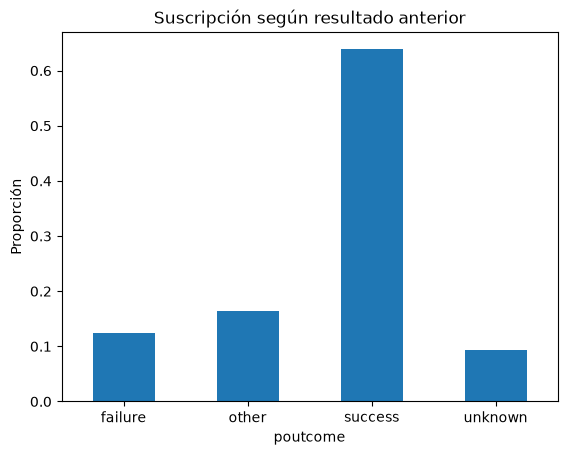

In [3]:
y_train.value_counts().sort_index().plot.bar(
    title="Suscripciones en entrenamiento"
)
plt.xticks([0, 1], ["No", "Sí"], rotation=0)
plt.ylabel("Registros")
plt.show()

X_train[["age", "balance", "campaign", "previous"]].hist(
    bins=30, figsize=(10, 6)
)
plt.tight_layout()
plt.show()

eda = X_train.copy()
eda["suscripcion"] = y_train
tasas = eda.groupby("poutcome")["suscripcion"].agg(["mean", "count"])
display(tasas.round(3))
tasas["mean"].plot.bar(title="Suscripción según resultado anterior")
plt.ylabel("Proporción")
plt.xticks(rotation=0)
plt.show()

## Interpretación breve

Las suscripciones son minoritarias. Por eso se comparan precisión, recall y F1, además de exactitud y ROC-AUC. Los saldos y conteos tienen colas largas; no se eliminan extremos sin evidencia de error. Los saldos negativos y `pdays=-1` tienen significado y se conservan. La selección de hiperparámetros usa validación; la prueba reservada no se consulta.

Fuente: Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

## Organización del proyecto

Las explicaciones de POO, herencia, polimorfismo, pruebas y eficiencia están en `docs/diseno.md`. El entrenamiento y la evaluación se mantienen fuera de este notebook. El README describe los comandos y el archivo `MLproject` declara la ejecución reproducible.